# 00 — Create your first baseline

**First prepare your dataset with [prepare_account_sample.ipynb](prepare_account_sample.ipynb), then start here.** You will train the generator, generate one complete synthetic dataset, and evaluate it against the real reference.

This notebook needs preprocessed Berka tables, not existing models or experiment results. It uses the toolkit's training/synthesis functions through shared helpers. The original workflow files remain references.

1. Install the declared environment from the repository terminal: `uv sync --locked --group tabular-data --inexact`.
2. Select the project's `.venv` notebook kernel. Run [prepare_account_sample.ipynb](prepare_account_sample.ipynb) to create the separate account-sampled dataset (500 accounts, seed 42 by default).
3. Preview this notebook with `RUN_NEW_TRIALS = False`. When ready for GPU work, change it to `True` and rerun cells in order.
4. After a successful baseline evaluation, open [guidance_strength_tuning.ipynb](guidance_strength_tuning.ipynb).

You execute the notebooks yourself. The baseline completed on 2026-10-29; recorded stage durations total about **34 min 08 s**, excluding evaluation. See the completed run record and conclusion below.

All 8 tables remain in the generator. The new dataset retains every raw transaction for the selected accounts. The baseline now reports full-table quality and overdraft/transaction quality together. Edit [dataset_settings.py](dataset_settings.py) to select another input/output dataset path before running. No original synthesized files are overwritten.

In [1]:
import os
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image
from IPython.display import display as show


ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
os.environ.setdefault("MPLCONFIGDIR", "/tmp/transaction-evaluation-matplotlib")
MULTI_TABLE = ROOT / "implementations/tabular_data/multi_table"

from implementations.tabular_data.multi_table.evaluation.transaction_evaluation import evaluate_saved_runs
from implementations.tabular_data.multi_table.experiments.dataset_settings import DATA_DIR as DEFAULT_DATA_DIR
from implementations.tabular_data.multi_table.experiments.tuning import (
    DEFAULT_EXPERIMENT_ROOT,
    DEFAULT_REPORT_ROOT,
    base_config,
    completed_runs,
    preview_trials,
    run_trials,
)


## 1. Baseline settings and input check

The baseline copies repository settings, with the same **70/20/10 internal split** for diffusion and guidance classifiers because they fit their preprocessing separately. Guidance is 1, training/sampling seeds are 42, and sample scale is 1 (full reference size).

Use the same input tables and experiment root across subsequent notebooks. A dedicated `transaction_tuning_from_scratch` directory keeps this workflow independent of older artifacts. Preprocessing already provides all required input tables; separate original training/synthesis notebook runs are unnecessary.

In [2]:
RUN_NEW_TRIALS = True  # Change to True yourself when ready for GPU training.
# Edit dataset_settings.py once to switch every notebook, or override here.
DATA_DIR = DEFAULT_DATA_DIR
EXPERIMENT_ROOT = DEFAULT_EXPERIMENT_ROOT
OUTPUT_ROOT = DEFAULT_REPORT_ROOT
BASE = base_config(fresh_training=True)
TRIALS = [BASE]  # One configuration, training seed 42 and sampling seed 42.

import json


meta_path = DATA_DIR / "dataset_meta.json"
if not meta_path.is_file():
    raise FileNotFoundError("Run prepare_account_sample.ipynb first, or select an existing processed DATA_DIR in dataset_settings.py.")
meta = json.loads(meta_path.read_text())
required = [meta_path, DATA_DIR / "preprocess_meta.json"]
for table in meta["tables"]:
    required += [DATA_DIR / f"{table}.csv", DATA_DIR / f"{table}_domain.json"]
missing = [str(path) for path in required if not path.is_file()]
if missing:
    raise FileNotFoundError(f"Missing preprocessed inputs: {missing}")
print(f"Inputs ready: {len(meta['tables'])} tables. No saved experiments or models are required.")

print(f"Selected processed dataset: {DATA_DIR}")


Inputs ready: 8 tables. No saved experiments or models are required.
Selected processed dataset: /home/coder/synthetic-data-bootcamp/implementations/tabular_data/multi_table/data/berka_accounts_500_seed42


/home/coder/synthetic-data-bootcamp/.venv/lib/python3.12/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


## 2. Preview the work

One baseline configuration trains models for every parent/table relation, then generates a full dataset. This is the controlled reference for later parameter changes. A preview does not train models or create synthetic data.

In [3]:
PLAN = preview_trials(TRIALS)
show(PLAN.drop(columns="config"))
show(pd.json_normalize(BASE, sep="."))
print("First execution: clustering, diffusion training, guidance-classifier training, and generation.")
print("Later identical executions reuse verified completed stages.")


,cluster,diffusion,model,sample,training_seed,sampling_seed,guidance,clusters
0,853598978302b1623751,f36140014b1759667004,f687bb4d5e41b2323d1c,dc077a94e7fe0fbd916a,42,42,1.0,50


,training_seed,sampling_seed,diffusion_config.d_layers,diffusion_config.dropout,diffusion_config.num_timesteps,diffusion_config.model_type,diffusion_config.iterations,diffusion_config.batch_size,diffusion_config.lr,diffusion_config.gaussian_loss_type,...,classifier_config.batch_size,classifier_config.iterations,classifier_config.data_split_ratios,sampling_config.batch_size,sampling_config.classifier_scale,sampling_config.sample_scale,matching_config.num_matching_clusters,matching_config.matching_batch_size,matching_config.unique_matching,matching_config.no_matching
0,42,42,"[512, 1024, 1024, 1024, 1024, 512]",0.0,500,mlp,5000,256,0.0006,mse,...,256,5000,"[0.7, 0.2, 0.1]",200,1.0,1.0,1,1000,True,False


First execution: clustering, diffusion training, guidance-classifier training, and generation.
Later identical executions reuse verified completed stages.


## 3. Create the baseline on GPU

Enable `RUN_NEW_TRIALS` in step 1 yourself when ready. Keep the default seeds and model settings for the first baseline. Changing those settings requires using the same revised baseline in subsequent notebooks.

Run one generating notebook at a time. Completed stages are reused; an interrupted stage records its failure and is not treated as complete. Inspect `status.json` before retrying with a fresh experiment root.

In [4]:
NEW_RUN_DIRS = []
if RUN_NEW_TRIALS:
    EXPERIMENT_ROOT.mkdir(parents=True, exist_ok=True)
    PLAN.drop(columns="config").to_csv(EXPERIMENT_ROOT / "plan_baseline.csv", index=False)
    NEW_RUN_DIRS = run_trials(TRIALS, DATA_DIR, EXPERIMENT_ROOT, device="cuda")
    show(pd.DataFrame({"saved_baseline": [str(path) for path in NEW_RUN_DIRS]}))
else:
    print("Preview only. To create the first baseline, set RUN_NEW_TRIALS = True and rerun in order on a GPU.")


INFO :      Training data ratio is 1, so the data will not be split into training and test sets.
INFO :      Train dataframe shape: (77, 15)
INFO :      Total dataframe shape: (77, 15)
INFO :      Numerical data shape: (77, 13)
INFO :      Categorical data shape: (77, 2)
INFO :      Training data ratio is 1, so the data will not be split into training and test sets.
INFO :      Train dataframe shape: (596, 4)
INFO :      Total dataframe shape: (596, 4)
INFO :      Numerical data shape: (596, 0)
INFO :      Categorical data shape: (596, 4)
INFO :      Training data ratio is 1, so the data will not be split into training and test sets.
INFO :      Train dataframe shape: (500, 2)
INFO :      Total dataframe shape: (500, 2)
INFO :      Numerical data shape: (500, 1)
INFO :      Categorical data shape: (500, 1)
INFO :      Training data ratio is 1, so the data will not be split into training and test sets.
INFO :      Train dataframe shape: (596, 1)
INFO :      Total dataframe shape: (596, 

Initialization 0
  Iteration 10
  Iteration 20
  Iteration 30
  Iteration 40
Initialization converged.


INFO :      Average agree rate: 0.23772569468255064
INFO :      Number of cluster centers: 34
INFO :      Clustering account -> order
INFO :      Average agree rate: 0.7480392156862745
INFO :      Number of cluster centers: 50
INFO :      Clustering account -> loan
INFO :      Average agree rate: 1.0
INFO :      Number of cluster centers: 51
INFO :      Clustering disp -> card
INFO :      Average agree rate: 1.0
INFO :      Number of cluster centers: 51
INFO :      Clustering account -> disp


Initialization 0
  Iteration 10
Initialization converged.
Initialization 0
Initialization converged.
Initialization 0
  Iteration 10
Initialization converged.
Initialization 0


INFO :      Average agree rate: 0.971
INFO :      Number of cluster centers: 50
INFO :      Clustering client -> disp


...

Initialization converged.
Initialization 0


INFO :      Average agree rate: 0.7826414493683933
INFO :      Number of cluster centers: 47
INFO :      Setting random seeds to 42.
INFO :      No cache_dir provided. Will not attempt to load or save transformed dataset from/to cache
INFO :      No NaN processing policy specified.


Initialization converged.


INFO :      Model params: ModelParameters(diffusion_parameters=DiffusionParameters(layers_dimensions=[512, 1024, 1024, 1024, 1024, 512], dropout=0.0, input_dimension=0, output_dimension=0, embedding_dimension=0, n_blocks=0, block_dimension=0, hidden_dimension=0, dropout_first=0, dropout_second=0), input_dimension=np.int64(17), num_classes=0, is_target_conditioned=<IsTargetConditioned.NONE: 'none'>)
INFO :      Getting model: mlp
INFO :      Step 500/5000 MLoss: 0.0 GLoss: 0.3275 Sum: 0.3275
INFO :      Step 1000/5000 MLoss: 0.0 GLoss: 0.2495 Sum: 0.2495
INFO :      Step 1500/5000 MLoss: 0.0 GLoss: 0.2175 Sum: 0.2175
INFO :      Step 2000/5000 MLoss: 0.0 GLoss: 0.1935 Sum: 0.1935
INFO :      Step 2500/5000 MLoss: 0.0 GLoss: 0.1821 Sum: 0.1821
INFO :      Step 3000/5000 MLoss: 0.0 GLoss: 0.1622 Sum: 0.1622
INFO :      Step 3500/5000 MLoss: 0.0 GLoss: 0.1536 Sum: 0.1536
INFO :      Step 4000/5000 MLoss: 0.0 GLoss: 0.1352 Sum: 0.1352
INFO :      Step 4500/5000 MLoss: 0.0 GLoss: 0.1209 Sum:

,saved_baseline
0,/home/coder/synthetic-data-bootcamp/implementa...


## 4. Evaluate the baseline on CPU

One random forest learns current negative-balance detection from real transactions. Separate real accounts provide its detector test set; the same detector evaluates generated transactions. Balance and IDs do not enter the predictors.

The report includes overdraft transfer, event counts/prevalence and uncertainty, transaction distributions, overdraft-only patterns, account counts, key integrity, and dates aligned to their original epochs. This is an exploratory transfer study; internal generator splits do not establish an independent relational outer holdout.

The full-table view covers distributions and missing/unknown values in all 8 tables, PK/FK integrity and child counts on all 8 edges, within/cross-table mixed correlations, and client–account relationships joined through `disp`. External counterparty identifiers are excluded from numerical quality scores. Tables are weighted equally in the marginal summaries.

Evaluating d32c2dce062b79cbbdc4


,average_precision,average_precision_low,average_precision_high,standardized_ap,overdraft_prevalence,transaction_ks,transaction_tvd,overdraft_numerical_ks,synthetic_transaction_before_account_rate
dataset,,,,,,,,,
real_test,0.2422,0.0005,0.3606,0.2422,0.0017,NaN,NaN,NaN,NaN
d32c2dce062b79cbbdc4,0.0059,0.0052,0.0071,0.0033,0.0031,0.0589,0.0229,0.3829,0.19


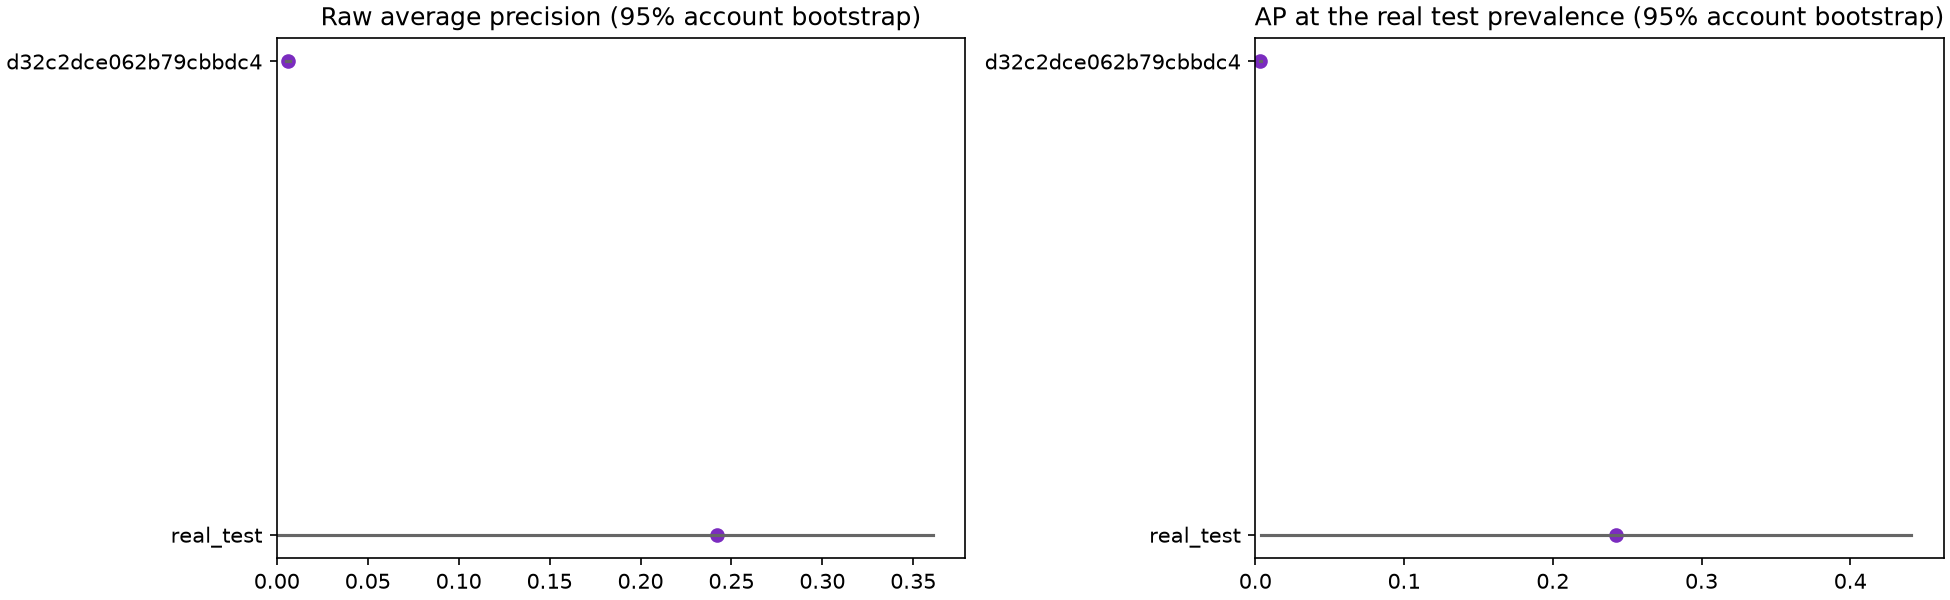

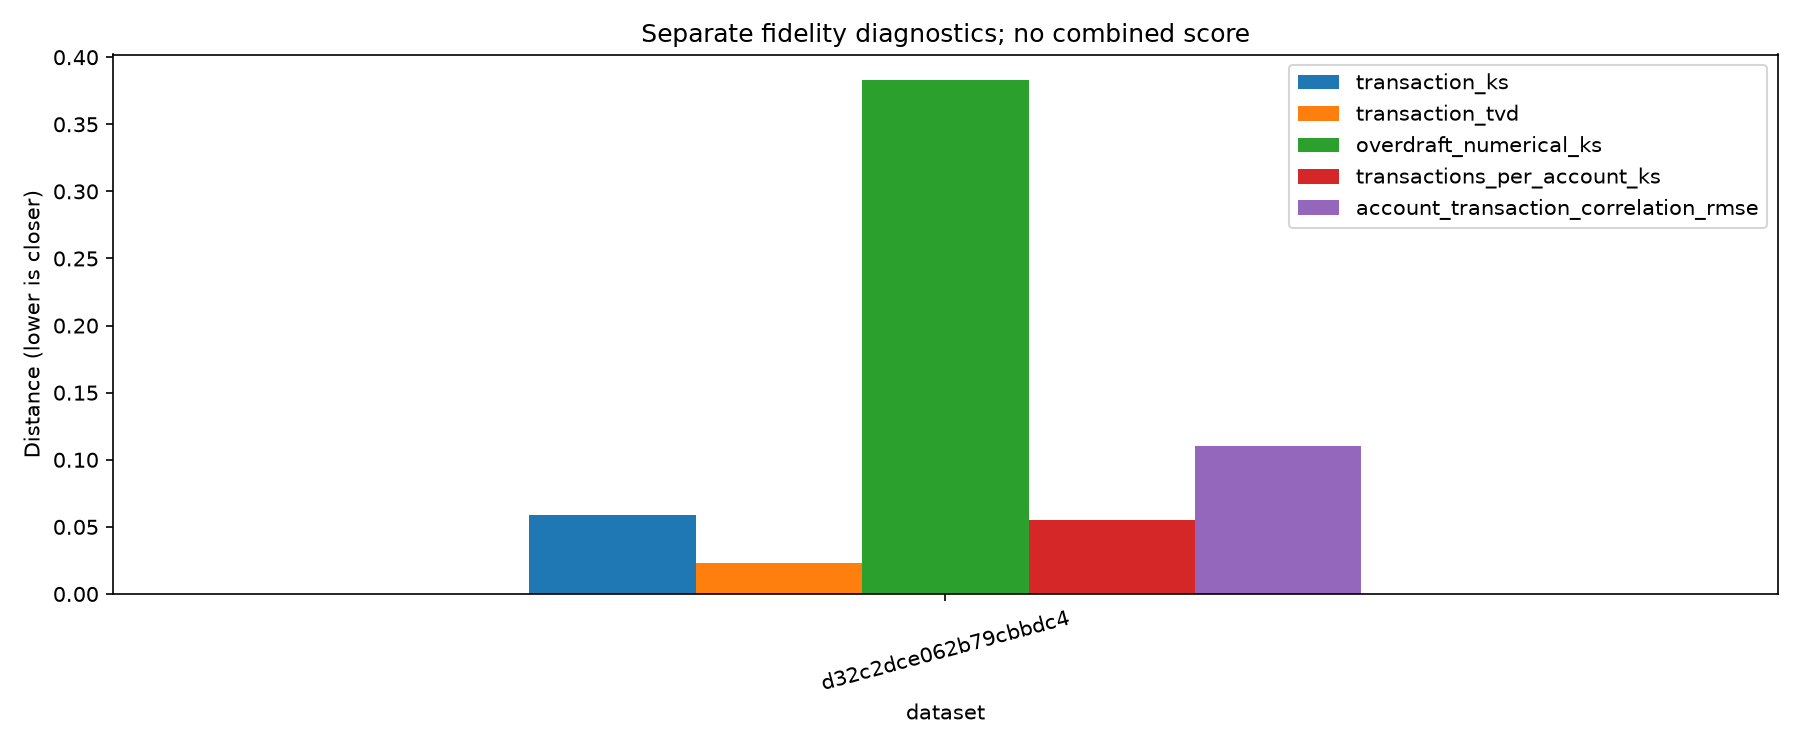

Baseline evaluated. Detailed report: /home/coder/synthetic-data-bootcamp/implementations/tabular_data/multi_table/results/experiments/transaction_overdraft_from_scratch/64f66493e1c5e4a1
Full multi-table quality — separate from overdraft transfer:


,all_table_count,all_edge_count,all_table_numerical_ks,all_table_categorical_tvd,all_cardinality_ks,all_relationship_correlation_rmse,all_min_fk_valid_rate,all_min_pk_unique_rate,multi_parent_correlation_rmse,multi_parent_joint_categorical_tvd,all_undefined_distribution_columns,all_undefined_correlation_pairs
dataset,,,,,,,,,,,,
d32c2dce062b79cbbdc4,8.0,8.0,0.0914,0.1043,0.0829,NaN,1.0,1.0,0.0649,0.1641,0.0,2.0


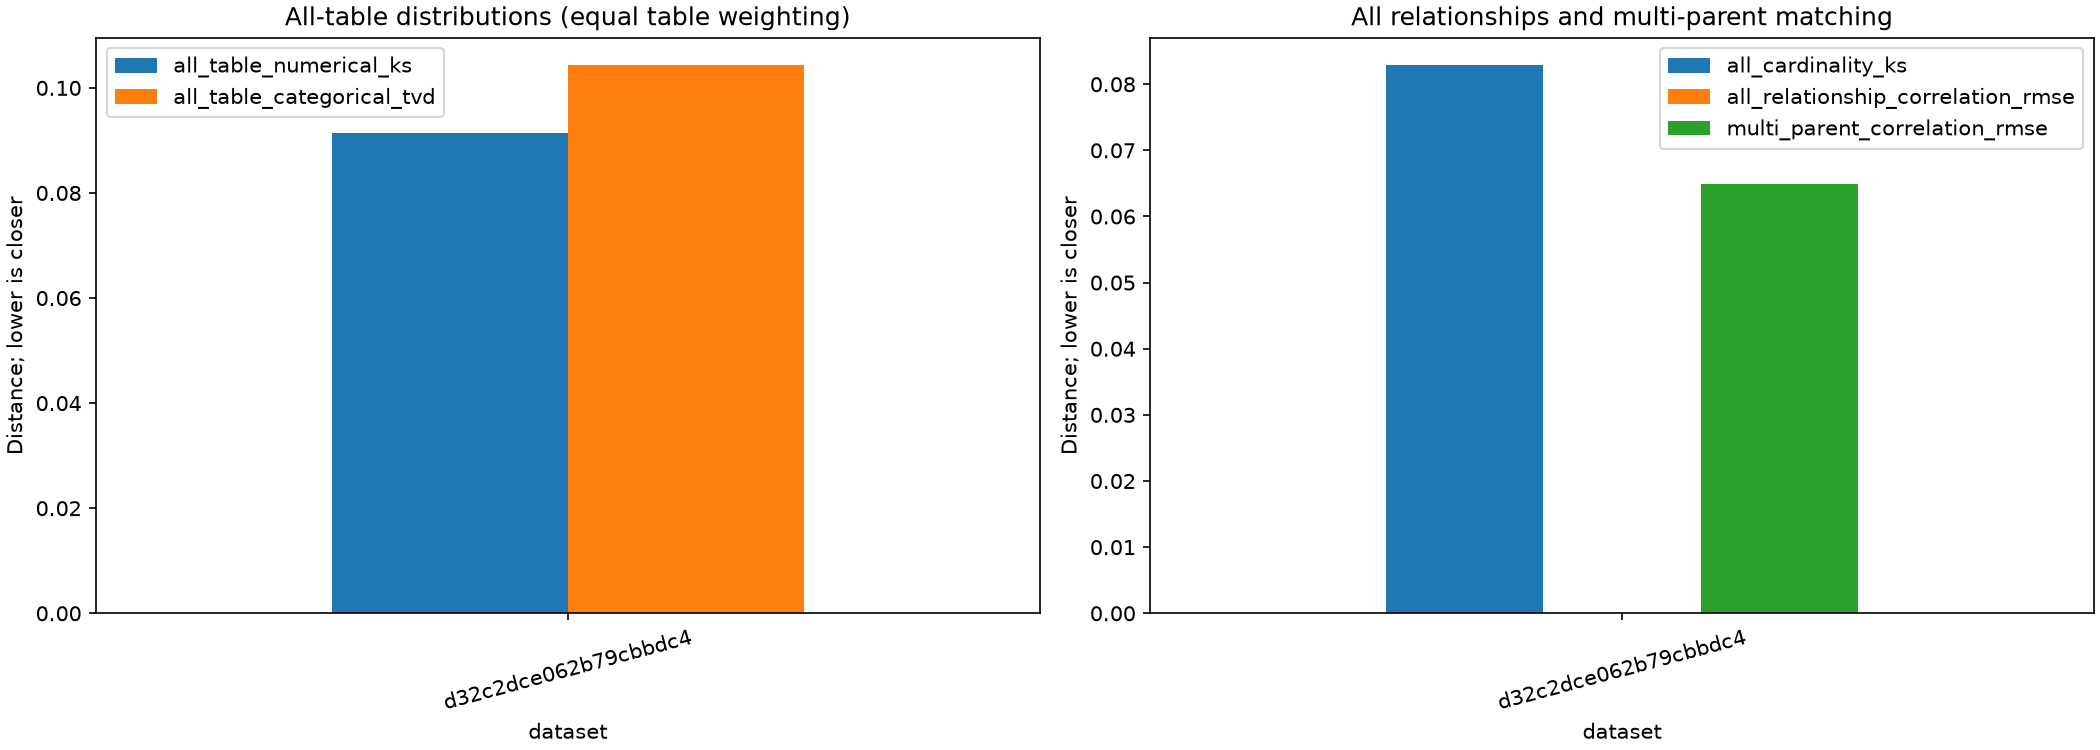

In [5]:
RUN_DIRS = completed_runs(DATA_DIR, EXPERIMENT_ROOT, configs=TRIALS) if DATA_DIR.is_dir() else []
comparison = None
REPORT_DIR = None
if RUN_DIRS:
    comparison, REPORT_DIR = evaluate_saved_runs(DATA_DIR, RUN_DIRS, OUTPUT_ROOT, bootstrap_repetitions=200)
    TRANSFER_AND_QUALITY = [
        "average_precision", "average_precision_low", "average_precision_high",
        "standardized_ap", "overdraft_prevalence", "transaction_ks", "transaction_tvd",
        "overdraft_numerical_ks", "synthetic_transaction_before_account_rate",
    ]
    show(comparison[TRANSFER_AND_QUALITY].round(4))
    show(Image(filename=str(REPORT_DIR / "transfer_intervals.png")))
    show(Image(filename=str(REPORT_DIR / "quality_comparison.png")))
    print(f"Baseline evaluated. Detailed report: {REPORT_DIR}")
else:
    print("No baseline has been generated yet. Complete step 3 before evaluating or tuning.")

if comparison is not None:
    FULL_TABLE_COLUMNS = [
        "all_table_count", "all_edge_count", "all_table_numerical_ks", "all_table_categorical_tvd",
        "all_cardinality_ks", "all_relationship_correlation_rmse", "all_min_fk_valid_rate",
        "all_min_pk_unique_rate", "multi_parent_correlation_rmse", "multi_parent_joint_categorical_tvd",
        "all_undefined_distribution_columns", "all_undefined_correlation_pairs",
    ]
    print("Full multi-table quality — separate from overdraft transfer:")
    show(comparison.loc[comparison.index != "real_test", FULL_TABLE_COLUMNS].round(4))
    show(Image(filename=str(REPORT_DIR / "multi_table_quality.png")))


## 5. Completed baseline record — 2026-10-29

**Status:** training, synthesis/matching, and evaluation completed successfully by the user. This is the reference for subsequent experiments, not a selected best configuration.

- **Input:** `berka_accounts_500_seed42`: 500 accounts, all 8 linked tables, 117,560 real transactions, and 247 overdraft rows across 28 accounts.
- **Saved run:** `d32c2dce062b79cbbdc4`; [resolved configuration](../results/experiments/transaction_tuning_from_scratch/samples/d32c2dce062b79cbbdc4/config.yaml) and [completed stage status](../results/experiments/transaction_tuning_from_scratch/samples/d32c2dce062b79cbbdc4/status.json).
- **Settings:** guidance **1.0**; training/sampling seeds **42/42**; **50** K-means + GMM clusters, parent scale **1.0**; 5,000 diffusion and classifier updates, 500 diffusion timesteps, aligned **70/20/10** internal splits, and full sample scale **1.0**.
- **Recorded stage durations:** clustering **20.0 s**; diffusion **226.9 s**; guidance-classifier stage **352.0 s**; synthesis/matching/saving **1,449.6 s**. Total **34 min 08 s**, excluding evaluation and work outside these stage timers. Device recorded as CUDA.

The overdraft detector uses a separate **80/20 account split**: 400 training accounts / 94,313 transactions / 208 overdrafts; 100 test accounts / 23,247 transactions / 39 overdrafts. Only **5 test accounts** contain overdrafts.

| Detector evaluation | Real account-held-out test | Synthetic baseline |
| --- | ---: | ---: |
| Transactions | 23,247 | 114,915 |
| Overdraft rows | 39 | 351 |
| Overdraft prevalence | 0.1678% | 0.3054% |
| Average precision (AP) | 0.2422 | 0.00595 |
| ROC-AUC | 0.8722 | 0.6249 |

The full real cohort prevalence is **0.2101%**. At the common real-test prevalence, synthetic standardized AP is **0.00327**. With 200 account-bootstrap draws, raw AP intervals are **0.0005–0.3606** for real test (199 valid draws) and **0.0052–0.0071** for synthetic (200 valid draws). The real estimate is especially uncertain because events are concentrated in only five test accounts; these intervals condition on one fitted detector and one generated dataset.

[Full comparison](../results/experiments/transaction_overdraft_from_scratch/64f66493e1c5e4a1/comparison.csv) · [Table breakdown](../results/experiments/transaction_overdraft_from_scratch/64f66493e1c5e4a1/d32c2dce062b79cbbdc4/all_table_scores.csv) · [Relationship breakdown](../results/experiments/transaction_overdraft_from_scratch/64f66493e1c5e4a1/d32c2dce062b79cbbdc4/all_edge_scores.csv)


## 6. Baseline conclusion

1. **The pipeline works, but valid keys do not establish realistic data.** All 8 tables and 8 relationships were evaluated; minimum PK uniqueness and FK validity are **1.0**, with no detected invalid feature values or unknown categories. Mean full-table numerical KS is **0.0914** and categorical TVD is **0.1043**. Table sizes differ: clients/dispositions are **435 vs 596** real, cards **59 vs 90**, and loans **52 vs 76**; these are baseline discrepancies to track, not evidence of their cause.
2. **Overdraft behavior is much less faithful than overall transaction distributions.** Overall transaction KS/TVD are **0.0589/0.0229**, but overdraft-only KS/TVD rise to **0.3829/0.3958**. Overdrafts occur in **215/469 synthetic accounts (45.8%)**, versus **28/500 real accounts (5.6%)**: they are spread across far more accounts. The low synthetic detector AP is another warning sign, although the wide real interval prevents a precise estimate of the transfer gap.
3. **Chronology and cross-table patterns need improvement.** **19.0%** of synthetic transactions precede account opening; the real rate is **0%**. District categorical TVD is **0.3052**; account→loan correlation RMSE is **0.2978**. Multi-parent client/account correlation RMSE is **0.0649**, with joint categorical TVD **0.1641**. Keep the baseline unchanged while assessing whether guidance variants improve these tradeoffs.

**Undefined score:** the global relationship-correlation RMSE is `NaN` because both `disp→card` pairs are undefined: disposition type is constant among card-linked rows in both datasets. This is an unscorable association, not zero error or a failed pipeline. Inspect the other edge scores individually.

**Next:** compare completed [guidance-strength trials](guidance_strength_tuning.ipynb) against guidance 1 using the same dataset, seeds, and saved models. Judge overdraft concentration, chronology, and both metric groups together. No hyperparameter winner or independent synthetic-trained→real utility result is established by this single baseline.
